# 05 · Valor del cliente (CLV) y churn parcial

**Sesión 5 · Valor del cliente** (ruta Paid Media, semana 9: CLV; catálogo: churn, supervivencia, CLV).

Preguntas:
1. ¿Cuánto va a gastar cada hogar en las próximas 13 semanas? ¿Le gana un modelo a "el próximo trimestre = el último"?
2. ¿Quién se está yendo de a poco (churn parcial: el gasto cae a menos de la mitad)?
3. ¿Dónde está la plata en riesgo: en qué segmentos y en qué hogares?

Calibración ene–sep 2017, validación oct–dic 2017 (decisión 006). `python -m growth_lab.clv`. Usa Complete Journey (`data/interim`); se publican solo agregados.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from growth_lab import db, clv

plt.rcParams.update({"figure.figsize": (9, 4), "axes.spines.top": False, "axes.spines.right": False})
s = clv.generar()
h = s["hogares"]
print(f"{len(h)} hogares · gasto real oct–dic: {h.gasto_real_13s.sum():,.0f} USD")

2446 hogares · gasto real oct–dic: 1,192,513 USD


## 1. Lo que ve el BG/NBD: tres números por hogar

- **x**: compras repetidas (días con compra − 1) · **t_x**: semana de la última compra · **T**: semanas desde la primera compra hasta el corte.

Con eso estima el **ritmo de compra** (λ) y la **probabilidad de abandonar** después de cada compra (p).

In [2]:
display(h[["x", "t_x", "T"]].describe().round(1))
par = s["clv_parametros"].set_index("modelo")
bg, gg = par.loc["bgnbd"], par.loc["gamma_gamma"]
print(f"Ritmo medio de compra r/α = {bg.r / bg.alpha:.2f} compras por semana")
print(f"Probabilidad media de abandonar tras una compra a/(a+b) = {bg.a / (bg.a + bg.b):.4f}")
print(f"Gasto medio por compra según Gamma-Gamma p·v/(q−1) = {gg.p * gg.v / (gg.q - 1):.1f} USD")
print(f"Correlación frecuencia–gasto medio = {par.corr_frecuencia_gasto.iloc[0]:.3f} (Gamma-Gamma supone ≈ 0: se cumple)")

,x,t_x,T
count,2446.0,2446.0,2446.0
mean,37.7,32.9,35.8
std,35.0,8.8,6.1
min,0.0,0.0,0.3
25%,12.0,32.1,36.1
50%,28.0,36.7,38.1
75%,52.0,38.0,38.7
max,242.0,38.9,39.0


Ritmo medio de compra r/α = 1.02 compras por semana
Probabilidad media de abandonar tras una compra a/(a+b) = 0.0010
Gasto medio por compra según Gamma-Gamma p·v/(q−1) = 37.3 USD
Correlación frecuencia–gasto medio = 0.006 (Gamma-Gamma supone ≈ 0: se cumple)


## 2. ¿Quién predice mejor el gasto de oct–dic?

`dif_mae_vs_ingenuo` < 0 = mejor que el ingenuo (IC 90% por bootstrap pareado).

,modelo,mae,rmse,r2,spearman,sesgo_total,captura_top_20,dif_mae_vs_ingenuo,dif_p05,dif_p95
0,ingenuo_ultimo_trimestre,180.532,277.398,0.751,0.814,-0.036,0.515,0.000,0.000,0.000
1,bgnbd_gamma_gamma,185.983,285.329,0.737,0.805,-0.050,0.507,5.451,0.597,10.273
2,lightgbm,176.930,274.386,0.757,0.823,-0.037,0.518,-3.602,-7.686,0.612


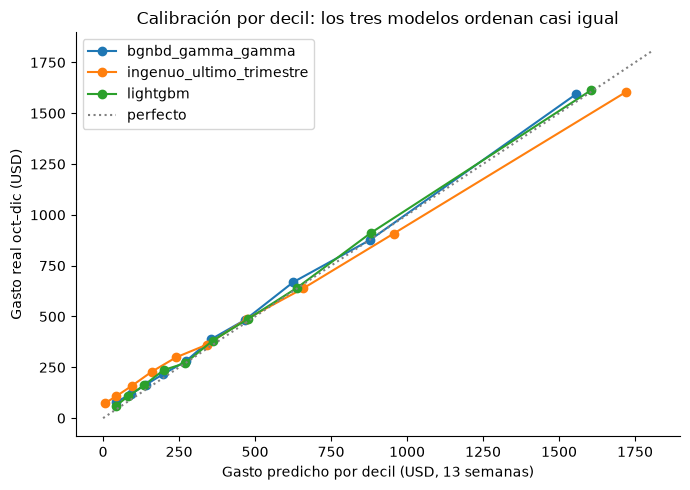

In [3]:
met = s["clv_metricas"]
display(met.round(3))
dec = s["clv_deciles"]
fig, ax = plt.subplots(figsize=(7, 5))
for nombre, g in dec.groupby("modelo"):
    ax.plot(g.pred_media, g.real_media, marker="o", label=nombre)
lim = [0, dec[["pred_media", "real_media"]].max().max() * 1.05]
ax.plot(lim, lim, color="grey", ls=":", label="perfecto")
ax.set_xlabel("Gasto predicho por decil (USD, 13 semanas)"); ax.set_ylabel("Gasto real oct–dic (USD)")
ax.set_title("Calibración por decil: los tres modelos ordenan casi igual"); ax.legend()
fig.tight_layout(); fig.savefig("../docs/img/clv_modelos.png", dpi=150); plt.show()

## 3. Churn parcial: ¿quién se está yendo de a poco?

In [4]:
display(s["clv_churn"].round(3))
s["clv_churn_importancia"].round(3)

,score,auc,tasa_churn,hogares
0,bgnbd_prob_no_vivo,0.622,0.18,2320
1,bgnbd_caida_esperada,0.503,0.18,2320
2,lightgbm_caida_esperada,0.514,0.18,2320
3,lightgbm_clasificador,0.682,0.18,2320


,variable,ganancia,pct
0,tendencia_13s,2333.685,0.127
1,recencia_sem,2205.732,0.120
2,sd_intervalo_dias,2012.785,0.109
3,pct_desc_tienda,1949.048,0.106
4,ticket,1808.455,0.098
5,gasto_4s,1713.268,0.093
6,gasto_13s,1554.329,0.084
7,compras_por_sem,1505.892,0.082
8,gasto_por_sem,1439.834,0.078
9,pct_cupon,968.445,0.053


## 4. Plata en riesgo por segmento (decisión 007: priorizar por hogar)

Gasto en riesgo de un hogar = P(churn) × la mitad de su gasto de jul–sep.

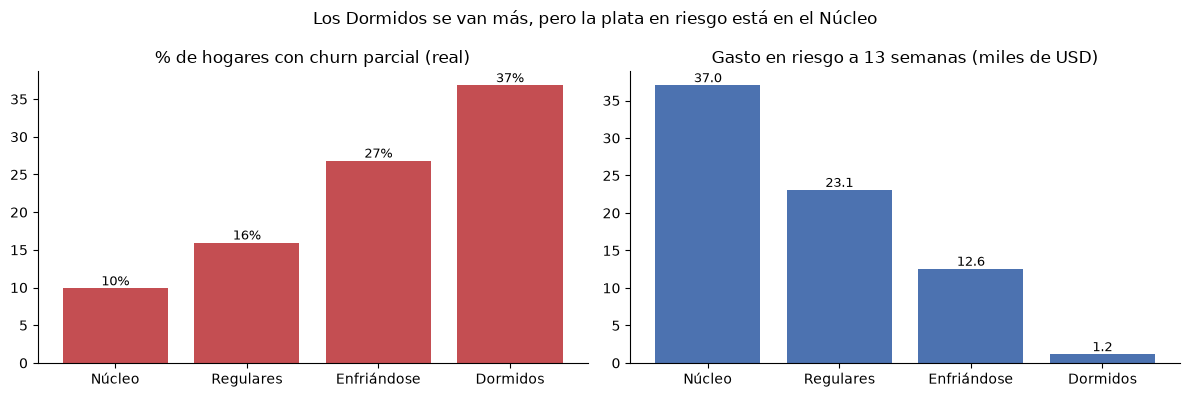

El 20% de hogares con más gasto en riesgo concentra el 58% del riesgo total


,hogares,clv_13s_lightgbm,tasa_churn_parcial,prob_churn_media,gasto_en_riesgo_total,hogares_en_top20_riesgo,pct_riesgo_en_top20
segmento,,,,,,,
Núcleo,778,957.400,0.099,0.110,37038.537,278,0.346
Regulares,820,360.159,0.160,0.164,23076.038,136,0.154
Enfriándose,590,160.020,0.268,0.279,12561.653,73,0.079
Dormidos,258,52.990,0.368,0.384,1171.944,2,0.001


In [5]:
seg = s["clv_por_segmento"].set_index("segmento").loc[["Núcleo", "Regulares", "Enfriándose", "Dormidos"]]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
a1.bar(seg.index, seg.tasa_churn_parcial * 100, color="#C44E52"); a1.set_title("% de hogares con churn parcial (real)")
a2.bar(seg.index, seg.gasto_en_riesgo_total / 1e3, color="#4C72B0"); a2.set_title("Gasto en riesgo a 13 semanas (miles de USD)")
for a, col, fmt in ((a1, seg.tasa_churn_parcial * 100, "{:.0f}%"), (a2, seg.gasto_en_riesgo_total / 1e3, "{:.1f}")):
    for i, v in enumerate(col):
        a.text(i, v, fmt.format(v), ha="center", va="bottom", fontsize=9)
fig.suptitle("Los Dormidos se van más, pero la plata en riesgo está en el Núcleo")
fig.tight_layout(); fig.savefig("../docs/img/clv_riesgo_segmento.png", dpi=150); plt.show()
top = h.nlargest(int(len(h) * 0.2), "gasto_en_riesgo")
print(f"El 20% de hogares con más gasto en riesgo concentra el {top.gasto_en_riesgo.sum() / h.gasto_en_riesgo.sum():.0%} del riesgo total")
seg[["hogares", "clv_13s_lightgbm", "tasa_churn_parcial", "prob_churn_media", "gasto_en_riesgo_total", "hogares_en_top20_riesgo", "pct_riesgo_en_top20"]].round(3)

## Mis conclusiones (Neider)

1. **Lo ingenuo es difícil de batir:** en un supermercado, "el próximo trimestre = el último" se equivoca en 180 USD por hogar; LightGBM baja a 177 (no significativo) y el BG/NBD sube a 186. Me quedo con LightGBM porque además sirve para el churn.
2. **El BG/NBD no encaja aquí:** supone que el cliente se va de golpe, y estima una probabilidad de abandonar de 0,1% por compra. En retail el cliente no se va: compra menos.
3. **El churn parcial sí se puede anticipar:** el clasificador llega a un AUC de 0,68, y lo que más pesa es la tendencia del gasto de las últimas 13 semanas, la recencia y la regularidad de las visitas.
4. **La plata en riesgo está en el Núcleo:** los Dormidos se van más (37%), pero el Núcleo concentra 37 mil de los 74 mil USD en riesgo. Por eso priorizo por hogar: el 20% con más riesgo junta el 58% de la plata.
5. **Próximo paso:** que la sesión 7 (uplift) me diga a cuáles de esos hogares la campaña les cambia la decisión, para no gastar en los que se quedan igual.